Pairs Trading


Loosely based on Gatev, Goetzmann, and Rouwenhorst(2006), Pairs Trading: Performance of a Relative-Value Arbitrage Rule

http://www-stat.wharton.upenn.edu/~steele/Courses/434/434Context/PairsTrading/PairsTradingGGR.pdf


By Hong Kee Sul



## Step 0. Setup

Import Modules


In [8]:
# Step 0-1

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn
import yfinance as yf
import statistics

from datetime import datetime
from dateutil.relativedelta import relativedelta


from IPython.display import display, HTML
from subprocess import getoutput


plt.style.use('fivethirtyeight')


Set choice of ticker pairs (Generated from Part 1)

Also set the mDate as the beginning of the trade Period

We will set the trading period duration as 6 months

In [ ]:
# Step 0-2
# All Parameters

ticker1 = 'BF-B'
ticker2 = 'STZ'
myTickerList2 = [ticker1, ticker2]

mDate = '2023-01-01' # Trading Start Date
# For Q6: repeat this pair for each trading start date below.
# Change mDate, rerun Steps 0–6, and save one results row per period (formation period at 12 months and trading period at 6 months.)
# '2023-01-01'
# '2023-07-01'
# '2024-01-01'
# '2024-07-01'
# '2025-01-01'
# '2025-07-01'

pairsFormationDuration = 12 # 12 months prior to trading
sDate =  (datetime.strptime(mDate, '%Y-%m-%d') + relativedelta(months=-pairsFormationDuration)).strftime( '%Y-%m-%d')
# Pairs Formation Start Date is 'pairsFormationDuration' months prior to the Trading Start Date

tradingPeriodDuration = 6 # 6 months after Trading Start Date
eDate =  (datetime.strptime(mDate, '%Y-%m-%d') + relativedelta(months=tradingPeriodDuration)).strftime( '%Y-%m-%d')
# Pairs Trading End Date is 'tradingPeriodDuration' months after the Trading Start Date

print('Pairs Formation Start Date', sDate)
print('Pairs Trading Start Date', mDate)
print('Pairs Trading End Date', eDate)


Pairs Formation Start Date 2022-01-01
Pairs Trading Start Date 2023-01-01
Pairs Trading End Date 2023-07-01


## Step 1. Download Formation Period Pricing Data

We must first download the data in the formation period, to calculate the STDEV of the stock return spread

This can be skipped if you have already done Part 1.

In [10]:
# Step 1-1

# 1. Download Data
# auto_adjust=False ensures 'Adj Close' is returned, fixing the KeyError
formationPeriodData = yf.download(myTickerList2, start=sDate, end=mDate, group_by='column', auto_adjust=False)

# 2. Select 'Adj Close'
# Handles the MultiIndex structure automatically
if isinstance(formationPeriodData.columns, pd.MultiIndex):
    formationPeriodData = formationPeriodData['Adj Close']

# 3. Clean Data
formationPeriodData = formationPeriodData.dropna(how='all')
formationPeriodData = formationPeriodData.dropna(axis='columns')

# 4. Cumulative Returns (Vectorized)
# Divides all columns by their first row in one step (no loop needed)
formationPeriodCumRet = formationPeriodData / formationPeriodData.iloc[0]

# 5. Calculate Standard Deviation of Spread
# Ensure we have the ticker names to access columns
ticker1 = myTickerList2[0]
ticker2 = myTickerList2[1]

# Use pandas built-in .std() instead of the statistics module for better performance
spread = formationPeriodCumRet[ticker1] - formationPeriodCumRet[ticker2]
stdev = spread.std()

print('Stdev of spread in the Formation Period', sDate, " to ", mDate, " is: ", stdev)

[*********************100%***********************]  1 of 2 completed
[*********************100%***********************]  1 of 2 completed

Stdev of spread in the Formation Period 2022-01-01  to  2023-01-01  is:  0.042471325820038215


Now let's visualize the Formation Period Cumulative Returns
(This was already done in Part 1)

We see that in the formation period, there is almost no deviation in the stock returns.

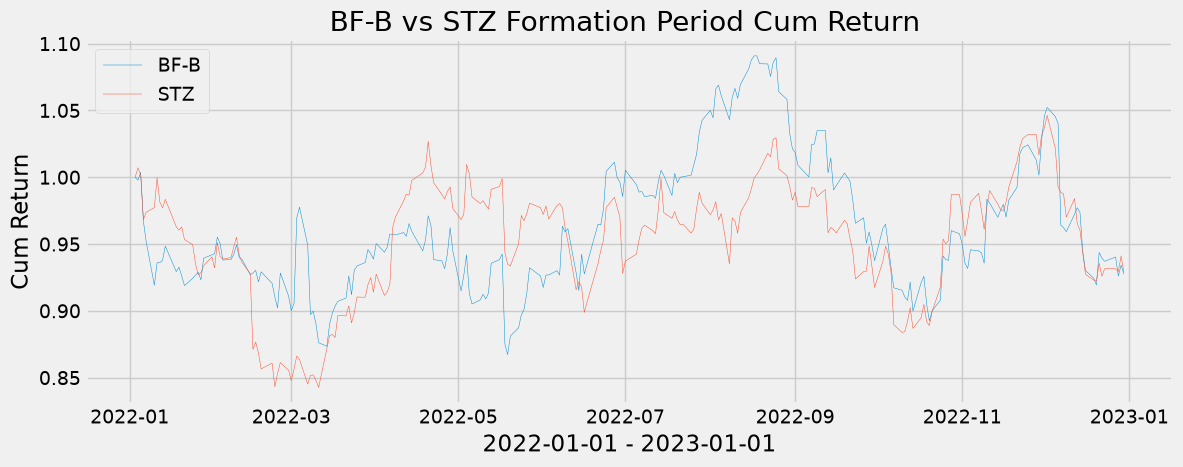

In [11]:
# Step 1-2

#visualize the data
plt.figure(figsize=(12.5, 4.5))
plt.plot(formationPeriodCumRet[ticker1], label = ticker1, linewidth = 0.35)
plt.plot(formationPeriodCumRet[ticker2], label = ticker2, linewidth = 0.35)
plt.title(ticker1+' vs ' + ticker2 + ' Formation Period Cum Return ')
plt.xlabel(sDate+" - "+mDate)
plt.ylabel('Cum Return')
plt.legend(loc='upper left')
plt.show()


## Part 2. Download Trading Period Pricing Data


Next we want to download data in the trading period

Make sure we also calculate the cumulative Returns

In [12]:
# Step 2-1


# Define list (assuming ticker1 and ticker2 are defined in your previous cells)
myTickerList2 = [ticker1, ticker2]

# 1. Download data
# auto_adjust=False ensures 'Adj Close' is returned
tradingPeriodData = yf.download(myTickerList2, start=mDate, end=eDate, group_by='column', auto_adjust=False)

# 2. Select 'Adj Close'
if isinstance(tradingPeriodData.columns, pd.MultiIndex):
    tradingPeriodData = tradingPeriodData['Adj Close']

# 3. Clean Data
tradingPeriodData = tradingPeriodData.dropna(how='all')
tradingPeriodData = tradingPeriodData.dropna(axis='columns')

# 4. Calculate Cumulative Returns (Vectorized)
# Divides the entire dataframe by the first row in one go
tradingPeriodCumRet = tradingPeriodData / tradingPeriodData.iloc[0]

print(tradingPeriodCumRet.head())

[*********************100%***********************]  2 of 2 completed

Ticker          BF-B       STZ
Date                          
2023-01-03  1.000000  1.000000
2023-01-04  1.008309  1.015641
2023-01-05  0.980766  0.916872
2023-01-06  0.991076  0.941256
2023-01-09  0.995384  0.946880


Now let's visualize the Trading Period Cumulative Returns


We see that unlike the formation period, there is some deviation in the stock returns.

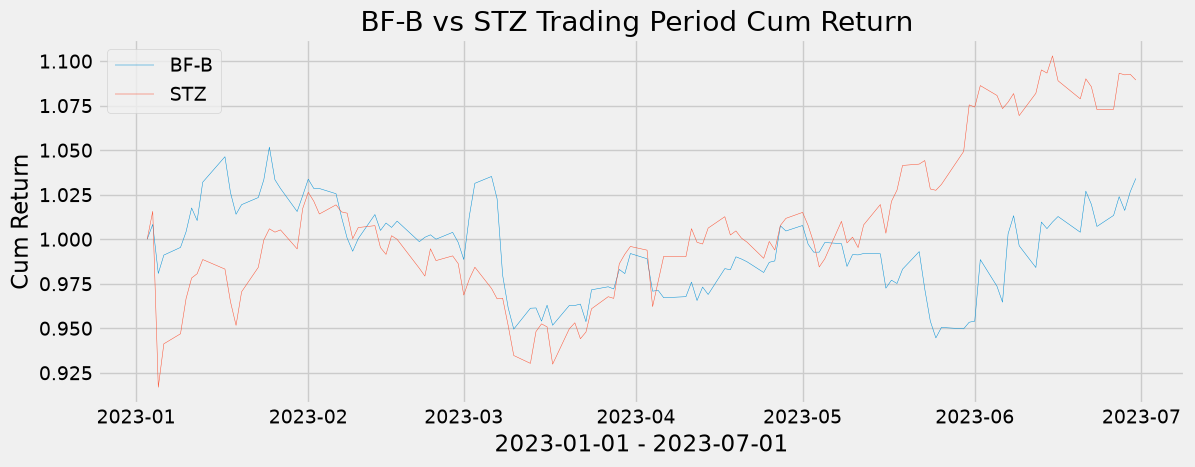

In [13]:
# Step 2-2
#visualize the data

plt.figure(figsize=(12.5, 4.5))
plt.plot(tradingPeriodCumRet[ticker1], label = ticker1, linewidth = 0.35)
plt.plot(tradingPeriodCumRet[ticker2], label = ticker2, linewidth = 0.35)
plt.title(ticker1+' vs ' + ticker2 + ' Trading Period Cum Return ')
plt.xlabel(mDate+" - "+eDate)
plt.ylabel('Cum Return')
plt.legend(loc='upper left')
plt.show()


## Step 3. Implement Trading Strategy

Now let's start out with the actual pairs trading to create buy(long) and sell(short) signals

Note here that we use 2 standard deviation(CONST1) as our Trading Initiation Signal.

Also note that we use 0(CONST2), when the cumulative returns converge, as the Trading Closing Signal.

You may choose to change CONST1/CONST2, if you see fit.

In [14]:
# Step 3-1

CONST1 = stdev*2
CONST2 = 0

def buy_sell(data, tick1, tick2):
  sigPriceBuy = []
  sigPriceSell = []
  flag = 0
  S1 = data[tick1]
  S2 = data[tick2]
  for i in range(len(data)):

    doNone = False
    if i == len(data)-1: #Last day of Trading Period
      if flag == 0:
        doNone = True
      elif flag == 1: # If we had a position open with short on Ticker1 and long on Ticker2 - Thus we must close position by long Ticker1 and short Ticker2
        sigPriceBuy.append([tick1, S1[i]])
        sigPriceSell.append([tick2, S2[i]])

      else: # If we had a position open with long on Ticker1 and short on Ticker2 - Thus we must close position by long Ticker2 and short Ticker1
        sigPriceBuy.append([tick2, S2[i]])
        sigPriceSell.append([tick1, S1[i]])

    else: # Not at the last day of Trading Period
      if flag ==0: # We are not in a position
        if (S1[i] - S2[i] > CONST1): # Flag1 means ticker1 is much higher than ticker2 - Thus short Ticker1 and long Ticker2
          sigPriceBuy.append([tick2, S2[i]])
          sigPriceSell.append([tick1, S1[i]])
          flag = 1
        elif (S2[i] - S1[i]> CONST1): # Flag2 means ticker2 is much higher than ticker1 - Thus short Ticker2 and long Ticker1
          sigPriceBuy.append([tick1, S1[i]])
          sigPriceSell.append([tick2, S2[i]])
          flag = 2
        else:
          doNone = True

      elif flag == 1: # We are in flag1 - we have shorted Ticker1 and longed Ticker2
        if (S1[i] - S2[i] < CONST2): # If close position signal is received, must long Ticker1 and short Ticker2
          sigPriceBuy.append([tick1, S1[i]])
          sigPriceSell.append([tick2, S2[i]])
          flag = 0
        else:
          doNone = True

      elif flag == 2:  # We are in flag2 - we have shorted Ticker2 and longed Ticker1
        if (S2[i] - S1[i] < CONST2): # If close position signal is received, must long Ticker2 and short Ticker1
          sigPriceBuy.append([tick2, S2[i]])
          sigPriceSell.append([tick1, S1[i]])
          flag = 0
        else:
          doNone = True

    if doNone:
      sigPriceBuy.append(['', np.nan])
      sigPriceSell.append(['', np.nan])

  return (sigPriceBuy, sigPriceSell)


Here is the Result of Our Strategy - Buy and Sell Signals

In [15]:
# Step 3-2
#Store the buy and sell data into a variable
#buySellResult = buy_sell(tradingPeriodCumRet, ticker1, ticker2)
buySellResult = buy_sell(tradingPeriodCumRet.reset_index(drop=True), ticker1, ticker2)

tradingPeriodCumRet['Buy_Signal_Price'] = [a[1] for a in buySellResult[0]]
tradingPeriodCumRet['Sell_Signal_Price'] = [a[1] for a in buySellResult[1]]
tradingPeriodCumRet['Buy_Signal_Ticker'] = [a[0] for a in buySellResult[0]]
tradingPeriodCumRet['Sell_Signal_Ticker'] = [a[0] for a in buySellResult[1]]


tradingPeriodCumRet.head()


Ticker,BF-B,STZ,Buy_Signal_Price,Sell_Signal_Price,Buy_Signal_Ticker,Sell_Signal_Ticker
Date,,,,,,
2023-01-03,1.000000,1.000000,NaN,NaN,,
2023-01-04,1.008309,1.015641,NaN,NaN,,
2023-01-05,0.980766,0.916872,NaN,NaN,,
2023-01-06,0.991076,0.941256,NaN,NaN,,
2023-01-09,0.995384,0.946880,NaN,NaN,,


But first, we need to check whether there are any buy signals

In [16]:
# Step 3-3

totalNumberOfTradingDays = len(tradingPeriodCumRet)
totalNumberOfBuys = tradingPeriodCumRet['Buy_Signal_Price'].count()

print('totalNumberOfTradingDays', totalNumberOfTradingDays)
print('totalNumberOfBuys', totalNumberOfBuys)

totalNumberOfTradingDays 124
totalNumberOfBuys 2


Now let's try to visualize our signals, along with the stock cumulative Returns

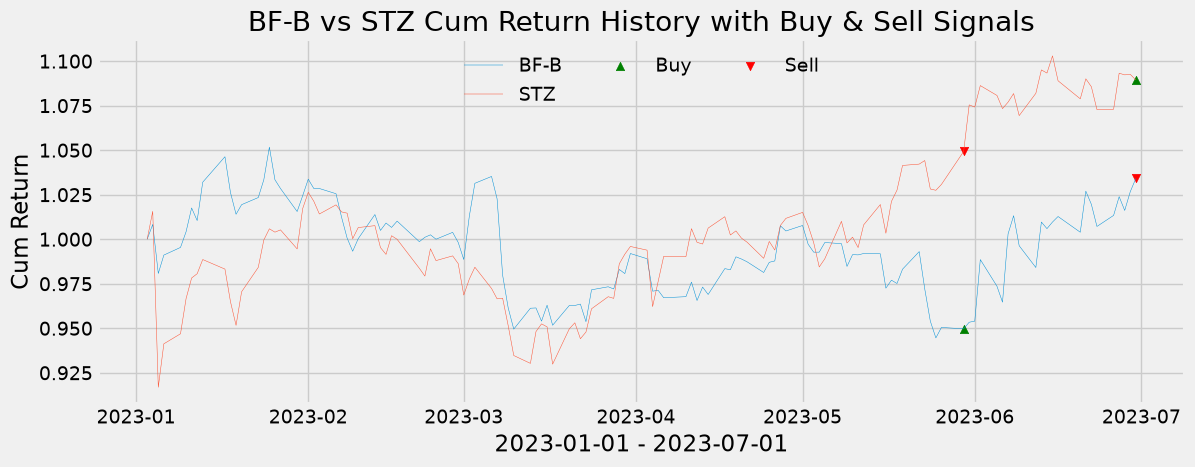

In [17]:
# Step 3-4
#Visualize the data and the stragey to buy and sell the stock

if totalNumberOfBuys != 0:

  plt.figure(figsize=(12.5, 4.5))
  plt.plot(  tradingPeriodCumRet[ticker1], label = ticker1, linewidth = 0.35)
  plt.plot(  tradingPeriodCumRet[ticker2], label = ticker2, linewidth = 0.35)

  plt.scatter( tradingPeriodCumRet.index, tradingPeriodCumRet['Buy_Signal_Price'], label = 'Buy', marker = '^', color = 'green')
  plt.scatter(tradingPeriodCumRet.index,  tradingPeriodCumRet['Sell_Signal_Price'], label = 'Sell', marker = 'v', color = 'red')

  plt.title(ticker1 + ' vs ' +  ticker2+' Cum Return History with Buy & Sell Signals')
  plt.xlabel(mDate+" - "+eDate)
  plt.ylabel('Cum Return')
  plt.legend(frameon=False, loc='upper center', ncol=3)
  plt.show()
else:
  print("No buys in the trading period! Do not proceed to Step 4!")

## Step 4. Calculate Long-Short Portfolio Returns from Pairs Trading Strategy

And from the Buy and Sell signals, let's try to calculate our Long/Short portfolio returns

In [18]:
# Step 4-1
# strategy return
def buy_sell_price(data):
	strategy = []
	flag = 0
	longPrice = 0
	shortPrice = 0
	longTicker = ''
	shortTicker = ''
	asset = 1
	multiple = 1

	for i in range(len(data)):
		#print(data.index[i], i, asset, multiple)

		if data['Buy_Signal_Ticker'][i] !='': #New position

			if flag == 0: # Open New Pair
				longPrice = data['Buy_Signal_Price'][i]
				shortPrice = data['Sell_Signal_Price'][i]
				longTicker = data['Buy_Signal_Ticker'][i]
				shortTicker = data['Sell_Signal_Ticker'][i]
				strategy.append(asset)
				flag = 1

			else: # Close Existing Pair
				longSideRet = data[longTicker][i]-longPrice
				shortSideRet = shortPrice-data[shortTicker][i]
				totRet = longSideRet + shortSideRet
				multiple = multiple * (1+totRet)
				asset = multiple
				strategy.append(asset)
				longPrice = 0
				shortPrice = 0
				longTicker = ''
				shortTicker = ''
				flag = 0

		else: # No new position

			if flag == 1: #Update Asset Value
				longSideRet = data[longTicker][i]-longPrice
				shortSideRet = shortPrice-data[shortTicker][i]
				totRet = longSideRet + shortSideRet
				asset = (1+totRet)*multiple
				strategy.append(asset)

			else: # Nothing Happens
				strategy.append(asset)

	return (strategy)

Here is the value of the Long/Short Portfolio Value

In [19]:
# Step 4-2
#pairs_strategy = buy_sell_price(tradingPeriodCumRet)
pairs_strategy = buy_sell_price(tradingPeriodCumRet.reset_index(drop=True))
tradingPeriodCumRet['pairs_strategy'] = pairs_strategy
tradingPeriodCumRet.head()

Ticker,BF-B,STZ,Buy_Signal_Price,Sell_Signal_Price,Buy_Signal_Ticker,Sell_Signal_Ticker,pairs_strategy
Date,,,,,,,
2023-01-03,1.000000,1.000000,NaN,NaN,,,1.0
2023-01-04,1.008309,1.015641,NaN,NaN,,,1.0
2023-01-05,0.980766,0.916872,NaN,NaN,,,1.0
2023-01-06,0.991076,0.941256,NaN,NaN,,,1.0
2023-01-09,0.995384,0.946880,NaN,NaN,,,1.0


Now let's try to visualize the profitability of our Long/Short pairs Trading strategy, with Simple Buy&Hold Returns of both stocks

In [20]:
# Step 4-3

mask = ~np.isnan(tradingPeriodCumRet['pairs_strategy'].values)
security_name = ticker1
strategy_cret = (tradingPeriodCumRet['pairs_strategy'].values[mask])
BH_cret1 = (tradingPeriodCumRet[ticker1].values[mask])/(tradingPeriodCumRet[ticker1].values[mask])[0]
BH_cret2 = (tradingPeriodCumRet[ticker2].values[mask])/(tradingPeriodCumRet[ticker2].values[mask])[0]
dates = tradingPeriodCumRet.index.values[mask]

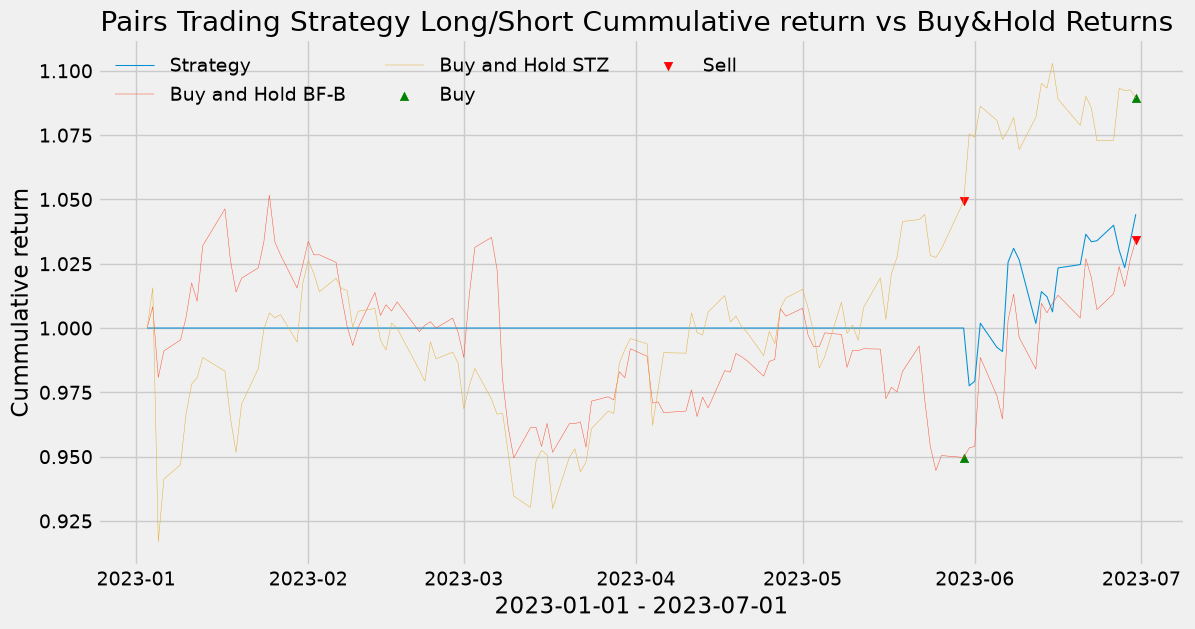

In [21]:


# Step 4-4
#Visualize the data and the stragey to buy and sell the stock
plt.figure(figsize=(12.5, 6.5))
plt.plot(dates, strategy_cret, label = 'Strategy', linewidth = 0.75)
plt.plot(dates, BH_cret1, label = 'Buy and Hold ' + ticker1, linewidth = 0.35)
plt.plot(dates, BH_cret2, label = 'Buy and Hold ' + ticker2, linewidth = 0.35)
plt.scatter( tradingPeriodCumRet.index, tradingPeriodCumRet['Buy_Signal_Price'], label = 'Buy', marker = '^', color = 'green')
plt.scatter(tradingPeriodCumRet.index,  tradingPeriodCumRet['Sell_Signal_Price'], label = 'Sell', marker = 'v', color = 'red')

plt.title('Pairs Trading Strategy Long/Short Cummulative return vs Buy&Hold Returns ')
plt.xlabel(mDate+" - "+eDate)
plt.ylabel('Cummulative return')
plt.legend(frameon=False, loc='upper left', ncol=3)
plt.show()

## Step 5. Risk Assessment - Pairs Trading Returns vs Buy and Hold Returns

Now, Let's try to examine the raw Return of our Pairs Trading Strategy compared with Buy&Hold Returns

In [22]:

# Step 5-1

mask = ~np.isnan(tradingPeriodCumRet['pairs_strategy'].values)
pairs_return = (tradingPeriodCumRet['pairs_strategy'].values[mask])[-1]/(tradingPeriodCumRet['pairs_strategy'].values[mask])[0]-1
BH_return1 = (tradingPeriodCumRet[ticker1].values[mask])[-1]/(tradingPeriodCumRet[ticker1].values[mask])[0]-1
BH_return2 = (tradingPeriodCumRet[ticker2].values[mask])[-1]/(tradingPeriodCumRet[ticker2].values[mask])[0]-1

print("Pairs Trading strategy return is","{0:.2%}".format(pairs_return), "\nand buy and hold strategy return is","{0:.2%}".format(BH_return1), "for",ticker1,"\nand buy and hold strategy return is","{0:.2%}".format(BH_return2), "for",ticker2,"from",mDate,"to",eDate+".")


Pairs Trading strategy return is 4.43% 
and buy and hold strategy return is 3.41% for BF-B 
and buy and hold strategy return is 8.94% for STZ from 2023-01-01 to 2023-07-01.


Now, Let's try to examine the  Return/Risk Nature of our Pairs Trading Strategy compared with Buy&Hold Returns

In [23]:

# Step 5-2

pairs_ret = strategy_cret[1:]/strategy_cret[:-1]-1
BH_ret1 = BH_cret1[1:]/BH_cret1[:-1]-1
BH_ret2 = BH_cret2[1:]/BH_cret2[:-1]-1

print("For",ticker1," and ", ticker2,"from",mDate,"to",eDate,\
      "\nPairs Trading strategy return:", "mean is","{0:.2%}".format(pairs_ret.mean()), "std. dev. is","{0:.2%}".format(pairs_ret.std())+".",\
      "\nBuy and hold strategy return for:", ticker1, "mean is","{0:.2%}".format(BH_ret1.mean()), "std. dev. is","{0:.2%}".format(BH_ret1.std())+"."      ,\
      "\nBuy and hold strategy return2 for:", ticker2, "mean is","{0:.2%}".format(BH_ret2.mean()), "std. dev. is","{0:.2%}".format(BH_ret2.std())+".")


For BF-B  and  STZ from 2023-01-01 to 2023-07-01 
Pairs Trading strategy return: mean is 0.04% std. dev. is 0.57%. 
Buy and hold strategy return for: BF-B mean is 0.03% std. dev. is 1.21%. 
Buy and hold strategy return2 for: STZ mean is 0.08% std. dev. is 1.43%.


## Step 6. Calculate Sharpte Ratio for our Pairs Trading Strategy

Finally,Let's try to examine the  Return/Risk Nature of our Pairs Trading Strategy compared with Buy&Hold Returns using the Sharpe Ratio.

But first, we need risk free return to calculate that.

In [24]:


# Step 6-1

# 1. Download Data
# auto_adjust=False is crucial to get 'Adj Close'
risk_free_rate = yf.download('^IRX', start=mDate, end=eDate, auto_adjust=False)

# 2. Flatten Columns (Safety Step)
# Even for single tickers, yfinance sometimes returns a MultiIndex (e.g., ('Adj Close', '^IRX')).
# This line flattens it so you just get ['Open', 'Close', 'Adj Close', ...]
if isinstance(risk_free_rate.columns, pd.MultiIndex):
    risk_free_rate.columns = risk_free_rate.columns.get_level_values(0)

# 3. Process Data
risk_free_rate = risk_free_rate.reset_index(drop=False)

# Now strictly select the columns we need
risk_free_rate = risk_free_rate[['Date', 'Adj Close']]

# 4. Calculation (Annual Yield -> Daily Decimal Return)
# IRX is a percentage (e.g., 5.00 for 5%). We divide by 100 to get decimal, and 250 for daily.
risk_free_rate['Adj Close'] = risk_free_rate['Adj Close'] / (250 * 100)

# 5. Rename and Re-index
risk_free_rate.columns = ['Date', 'rf']
risk_free_rate = risk_free_rate.set_index('Date')

print(risk_free_rate.head())

[*********************100%***********************]  1 of 1 completed

                  rf
Date                
2023-01-03  0.000170
2023-01-04  0.000176
2023-01-05  0.000180
2023-01-06  0.000180
2023-01-09  0.000179


And we must merge the Risk Free Return with our Data

In [25]:

# Step 6-2
# Merge
risk_free_rate['date'] = risk_free_rate.index
tradingPeriodCumRet['date'] = tradingPeriodCumRet.index

tradingPeriodCumRetMerged = pd.merge(tradingPeriodCumRet, risk_free_rate, how='left',on = 'date',indicator=True)
#print(tradingPeriodCumRet)

Finally,Let's try to examine the  Return/Risk Nature of our Pairs Trading Strategy compared with Buy&Hold Returns using the Sharpe Ratio.


In [26]:

# Step 6-3

"""
rf = (tradingPeriodCumRetMerged['rf'].values[mask])[1:]
for i in range(len(rf)):
  prev_rf = 0
  if ~np.isnan(rf[i]):
    prev_rf = rf[i]
  if np.isnan(rf[i]):
    rf[i] = prev_rf



BH_excess_ret1 = BH_ret1-rf
BH_excess_ret2 = BH_ret2-rf
#print(BH_excess_ret)

mask2 = (pairs_ret!=0)
strategy_excess_ret = pairs_ret
strategy_excess_ret[mask2] = (pairs_ret-rf)[mask2]

"""

rf = (tradingPeriodCumRetMerged['rf'].values[mask])[1:]
# Days with no T-bill quote (bond-market holidays) take the previous day's rate
rf = pd.Series(rf).ffill().fillna(0).values

BH_excess_ret1 = BH_ret1-rf
BH_excess_ret2 = BH_ret2-rf

# The pairs position is long one stock and short the other with equal money,
# so it needs no capital of its own: its return is already an excess return.
strategy_excess_ret = pairs_ret



print("For",ticker1, " vs ", ticker2, "from",mDate,"to",eDate,\
      "\nPairs Trading strategy excess return:", "mean is","{0:.2%}".format(strategy_excess_ret.mean()), \
      "std. dev. is","{0:.2%}".format(strategy_excess_ret.std()), "daily Sharpe ratio is","{0:.2}".format(strategy_excess_ret.mean()/strategy_excess_ret.std())+".",\
      "\nBuy and hold strategy excess return:", ticker1, "mean is","{0:.2%}".format(BH_excess_ret1.mean()), \
      "std. dev. is","{0:.2%}".format(BH_excess_ret1.std()), "daily Sharpe ratio is","{0:.2}".format(BH_excess_ret1.mean()/BH_excess_ret1.std())+".", \
"\nBuy and hold strategy excess return:", ticker2, "mean is","{0:.2%}".format(BH_excess_ret2.mean()), \
      "std. dev. is","{0:.2%}".format(BH_excess_ret2.std()), "daily Sharpe ratio is","{0:.2}".format(BH_excess_ret2.mean()/BH_excess_ret2.std())+".")



For BF-B  vs  STZ from 2023-01-01 to 2023-07-01 
Pairs Trading strategy excess return: mean is 0.04% std. dev. is 0.57% daily Sharpe ratio is 0.065. 
Buy and hold strategy excess return: BF-B mean is 0.02% std. dev. is 1.21% daily Sharpe ratio is 0.013. 
Buy and hold strategy excess return: STZ mean is 0.06% std. dev. is 1.43% daily Sharpe ratio is 0.043.
